# Train vs Validation — Generalization and Overfitting

Learn to separate parameter fitting from model evaluation, diagnose deliberate overfitting, restore a checkpoint with early stopping, and compare weight decay and model capacity. Run from a fresh kernel in order; all imports, seeds, data, and models are defined here.

Training loss measures fit to observed examples. Validation loss measures transfer to held-out examples and guides the choices in this chapter. Expect that the lowest training loss will not always identify the best model.

## Independent setup

Import PyTorch, layers, optimizers, and plotting tools, then set seed 42. This notebook creates its own datasets and models. Expect repeatable runs in the same environment without executing the first notebook.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1


## Create noisy regression data

Generate 200 examples of $y=3x+2+\epsilon$, using normal noise scaled by 0.5. Both tensors have shape `[200, 1]`. Noise models imperfect observations; expect a recoverable linear trend with residual error.

In [3]:
# Create a larger synthetic regression dataset
# so we can split it into training and validation sets.

torch.manual_seed(42)

x_all = torch.linspace(-3, 3, 200).reshape(-1, 1)

# Add random noise to make the problem imperfect,
# similar to real-world observations.
noise = 0.5 * torch.randn(200, 1)

y_all = 3 * x_all + 2 + noise

print("x shape:", x_all.shape)
print("y shape:", y_all.shape)

x shape: torch.Size([200, 1])
y shape: torch.Size([200, 1])


## Shuffle before splitting

Randomly permute the sorted inputs, then allocate 80% to training and 20% to validation. This helps both subsets cover the full input range; a contiguous split would test different regions instead. Expect 160 training and 40 validation examples. Random splitting suits this synthetic setting; temporal or grouped data may require a different split.

In [4]:
# Randomly shuffle indices before splitting so both sets
# cover the full x-range rather than separate regions.

torch.manual_seed(42)

indices = torch.randperm(len(x_all))

train_size = int(0.8 * len(x_all))

train_indices = indices[:train_size]
val_indices = indices[train_size:]

x_train = x_all[train_indices]
y_train = y_all[train_indices]

x_val = x_all[val_indices]
y_val = y_all[val_indices]

print("Training examples:", len(x_train))
print("Validation examples:", len(x_val))

Training examples: 160
Validation examples: 40


## Check split coverage

Plot both subsets to check that each spans the input range. Expect overlapping coverage of the same noisy linear relationship, rather than two separated regions.

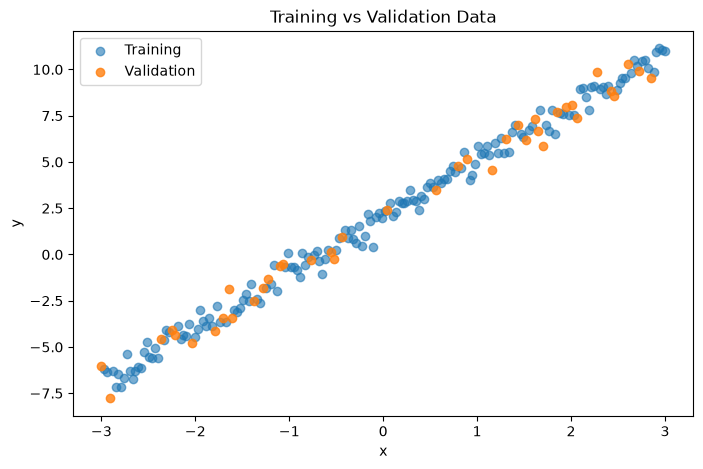

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x_train.numpy(),
    y_train.numpy(),
    alpha=0.6,
    label="Training"
)

plt.scatter(
    x_val.numpy(),
    y_val.numpy(),
    alpha=0.8,
    label="Validation"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Training vs Validation Data")
plt.legend()
plt.show()

The plot shows both subsets distributed across the input range. The held-out examples can now measure transfer within the same synthetic problem.

## Training and validation semantics

Only the 160 training examples contribute to backward passes and parameter updates. The 40 validation examples are evaluated under `torch.no_grad()`, without parameter updates. Expect both losses to decrease for this well-specified linear model, with residual error from noise.

Training loss is recorded before each optimizer step; validation loss is evaluated afterward. Thus the paired curves are not measured at precisely the same parameter state.

Later, validation selects checkpoints and hyperparameters. It therefore influences model selection even though it does not supply training gradients. An untouched test set would be needed for a final assessment after those choices. `model.eval()` sets evaluation behavior for layers such as dropout; `torch.no_grad()` separately disables graph recording.

In [6]:
torch.manual_seed(42)

model = nn.Linear(1, 1)

loss_fn = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.05
)

epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):
    # Training

    # Clear old gradients
    optimizer.zero_grad()

    # Forward pass using ONLY training data
    train_pred = model(x_train)

    # Training loss
    train_loss = loss_fn(train_pred, y_train)

    # Compute gradients
    train_loss.backward()

    # Update model parameters
    optimizer.step()

    # Validation

    # Validation is evaluation only.
    # We do not need to build an autograd graph here.
    with torch.no_grad():
        val_pred = model(x_val)
        val_loss = loss_fn(val_pred, y_val)

    # Save both losses for visualization
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f}"
        )

Epoch   0 | Train Loss: 16.2976 | Val Loss: 9.4294
Epoch  10 | Train Loss: 0.4062 | Val Loss: 0.4861
Epoch  20 | Train Loss: 0.2278 | Val Loss: 0.3833
Epoch  30 | Train Loss: 0.2075 | Val Loss: 0.3778
Epoch  40 | Train Loss: 0.2051 | Val Loss: 0.3796
Epoch  50 | Train Loss: 0.2048 | Val Loss: 0.3806
Epoch  60 | Train Loss: 0.2047 | Val Loss: 0.3810
Epoch  70 | Train Loss: 0.2047 | Val Loss: 0.3812
Epoch  80 | Train Loss: 0.2047 | Val Loss: 0.3812
Epoch  90 | Train Loss: 0.2047 | Val Loss: 0.3813


In [7]:
print("Final weight:", model.weight.item())
print("Final bias:", model.bias.item())

print("Final training loss:", train_losses[-1])
print("Final validation loss:", val_losses[-1])

Final weight: 2.997594118118286
Final bias: 2.034263849258423
Final training loss: 0.2047184407711029
Final validation loss: 0.3812730610370636


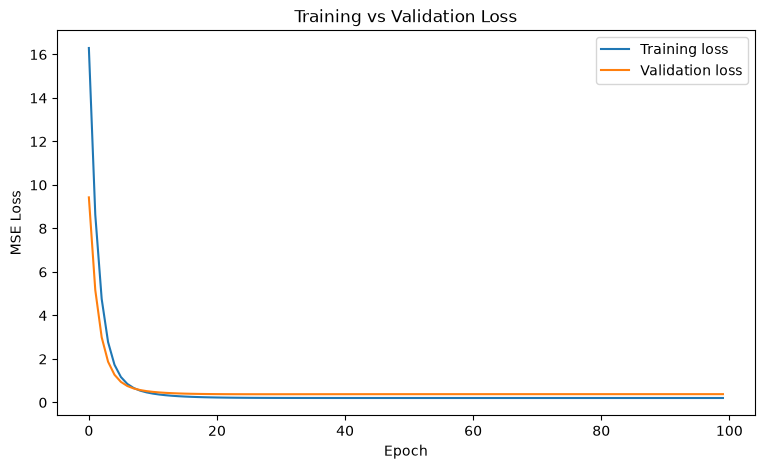

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses,
    label="Training loss"
)

plt.plot(
    val_losses,
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

## Train vs Validation — Interpretation

The final model learned:

```text
w = 2.9976
b = 2.0343
```

which is very close to the underlying synthetic relationship:

```text
w ≈ 3
b ≈ 2
```

The final losses were:

```text
training loss   = 0.2047
validation loss = 0.3813
```

### What happened during training?

Both losses decreased rapidly:

```text
training loss   ↓
validation loss ↓
```

and eventually stabilized.

This means the model was not only improving on the examples used for training.

It was also improving on examples that were not used to update its parameters.

That is evidence of **generalization**.

---

## Why is validation loss higher?

The validation loss is somewhat higher than the training loss.

This is not automatically a problem.

The model parameters are optimized directly using the training data:

```text
training data
      ↓
compute training loss
      ↓
backward()
      ↓
update parameters
```

The validation data never participates in parameter updates.

Therefore, it is normal for the model to perform somewhat better on the data it
was explicitly optimized against.

The data also contains random noise, so the exact difficulty of the training and
validation samples will differ.

---

## What would overfitting look like?

A typical overfitting pattern would look like:

```text
training loss
↓
↓
↓
↓

validation loss
↓
↓
then
↑
↑
```

In that situation, the model continues improving on the training set while
becoming worse on unseen examples.

Conceptually:

```text
early training
→ learn useful underlying pattern

too much fitting / too much capacity
→ start modeling details specific to training examples

training performance improves

but

validation performance deteriorates
```

Our current model does not show that behavior.

Instead:

```text
training loss   → low and stable
validation loss → low and stable
```

So this simple linear model appears to generalize well.

---



## Deliberately Creating Overfitting

The current model is:

```text
1 input
↓
1 linear output
```

with only two learnable parameters:

```text
weight
bias
```

This model has very limited capacity.

To make overfitting easier to observe, we will intentionally create a difficult
training setup:

```text
very small training set
+
noisy observations
+
much more flexible model
+
many training epochs
```

The goal is not to build a better model.

The goal is to create a controlled failure case and observe the difference
between:

```text
fitting the training data
and
generalizing to unseen data
```

Create $y=\sin(2x)+0.3x+\epsilon$ with noise scaled by 0.35 and a shuffled 20/180 split. Expect the tiny training subset to be sparse, making noise fitting easier for a flexible network.

In [9]:
# Generate a nonlinear dataset so a larger model has something flexible to learn.
torch.manual_seed(42)

x_overfit = torch.linspace(-3, 3, 200).reshape(-1, 1)

noise = 0.35 * torch.randn(200, 1)

y_overfit = (
    torch.sin(2 * x_overfit)
    + 0.3 * x_overfit
    + noise
)

# Randomize the examples before splitting
indices = torch.randperm(len(x_overfit))

# Deliberately use only 20 examples for training
train_indices = indices[:20]

# Use the remaining 180 examples for validation
val_indices = indices[20:]

x_train_small = x_overfit[train_indices]
y_train_small = y_overfit[train_indices]

x_val_large = x_overfit[val_indices]
y_val_large = y_overfit[val_indices]

print("Training examples:", len(x_train_small))
print("Validation examples:", len(x_val_large))

Training examples: 20
Validation examples: 180


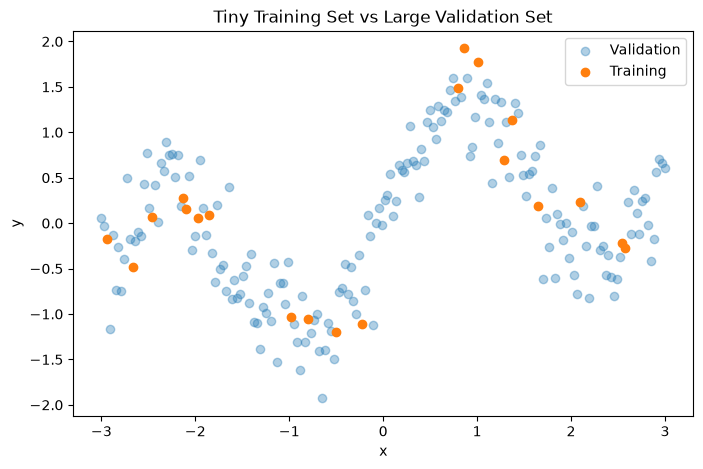

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x_val_large.numpy(),
    y_val_large.numpy(),
    alpha=0.35,
    label="Validation"
)

plt.scatter(
    x_train_small.numpy(),
    y_train_small.numpy(),
    label="Training"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Tiny Training Set vs Large Validation Set")
plt.legend()
plt.show()

## High-Capacity Model for an Overfitting Experiment

To make overfitting easier to observe, we will intentionally use a model with
far more capacity than the tiny training set requires.

The model will contain multiple nonlinear layers:

```text
1 input
↓
64 hidden units
↓
64 hidden units
↓
64 hidden units
↓
1 output
```

The hidden layers use ReLU activations.

This gives the model enough flexibility to fit complicated shapes and possibly
memorize details of the small training set.

The goal is not to claim that deeper models are bad.

The goal is to observe what can happen when:

```text
model capacity
>>
amount of training data
```

We will track both:

```text
training loss
validation loss
```

If the model overfits, we expect something like:

```text
training loss
↓
↓
↓
continues improving

validation loss
↓ initially
then ↑
```

The point where validation loss is lowest may occur well before training loss is
fully minimized.

In [11]:
# Use the same initialization every time for reproducibility.
torch.manual_seed(42)

# Intentionally high-capacity model for a tiny training set.
overfit_model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    overfit_model.parameters(),
    lr=0.01
)

print(overfit_model)

Sequential(
  (0): Linear(in_features=1, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=1, bias=True)
)


In [12]:
# Count all learnable scalar parameters in the model.
num_parameters = sum(
    p.numel()
    for p in overfit_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", num_parameters)
print("Training examples:", len(x_train_small))

Trainable parameters: 8513
Training examples: 20


The printed count is 8,513 trainable parameters for 20 training examples. This makes memorization plausible, but the validation curve is the evidence that determines whether overfitting actually occurs.

## Train the flexible model

Train for 2,000 epochs and monitor both MSE curves. Expect training error to keep falling while validation eventually worsens. Linear and log-scale plots show the gap at different scales; the best validation epoch need not be the final epoch.

In [13]:
epochs = 2000

train_losses_overfit = []
val_losses_overfit = []

for epoch in range(epochs):
    # Training
    overfit_model.train()

    optimizer.zero_grad()

    train_pred = overfit_model(x_train_small)
    train_loss = loss_fn(train_pred, y_train_small)

    train_loss.backward()
    optimizer.step()

    # Validation
    overfit_model.eval()

    with torch.no_grad():
        val_pred = overfit_model(x_val_large)
        val_loss = loss_fn(val_pred, y_val_large)

    train_losses_overfit.append(train_loss.item())
    val_losses_overfit.append(val_loss.item())

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Train Loss: {train_loss.item():.6f} | "
            f"Val Loss: {val_loss.item():.6f}"
        )

Epoch    0 | Train Loss: 0.807625 | Val Loss: 0.555900
Epoch  200 | Train Loss: 0.011386 | Val Loss: 0.341375
Epoch  400 | Train Loss: 0.000823 | Val Loss: 0.344774
Epoch  600 | Train Loss: 0.000143 | Val Loss: 0.333432
Epoch  800 | Train Loss: 0.006887 | Val Loss: 0.319323
Epoch 1000 | Train Loss: 0.001447 | Val Loss: 0.353515
Epoch 1200 | Train Loss: 0.000417 | Val Loss: 0.350970
Epoch 1400 | Train Loss: 0.000193 | Val Loss: 0.346176
Epoch 1600 | Train Loss: 0.000090 | Val Loss: 0.351515
Epoch 1800 | Train Loss: 0.000113 | Val Loss: 0.341827


In [14]:
best_val_loss = min(val_losses_overfit)
best_epoch = val_losses_overfit.index(best_val_loss)

print("Final training loss:", train_losses_overfit[-1])
print("Final validation loss:", val_losses_overfit[-1])

print()
print("Best validation loss:", best_val_loss)
print("Best validation epoch:", best_epoch)

Final training loss: 0.00023109601170290262
Final validation loss: 0.33860889077186584

Best validation loss: 0.22429610788822174
Best validation epoch: 12


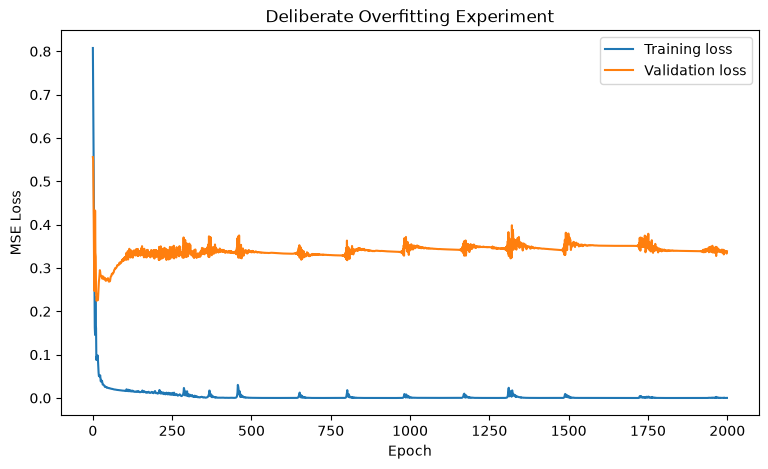

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses_overfit,
    label="Training loss"
)

plt.plot(
    val_losses_overfit,
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Deliberate Overfitting Experiment")
plt.legend()
plt.show()

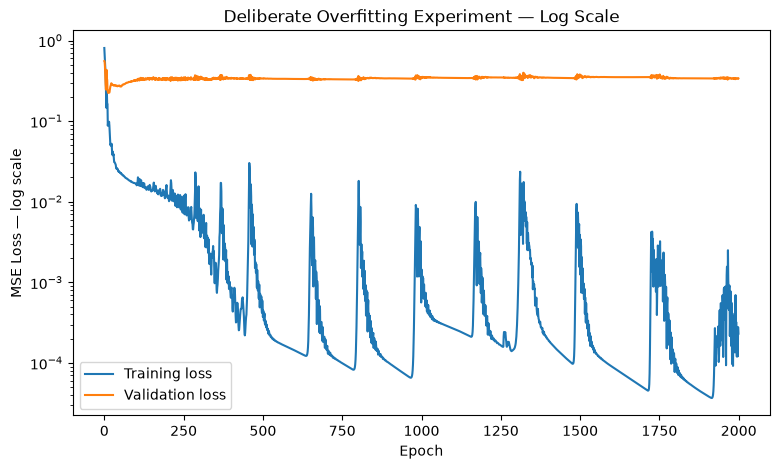

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses_overfit,
    label="Training loss"
)

plt.plot(
    val_losses_overfit,
    label="Validation loss"
)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss — log scale")
plt.title("Deliberate Overfitting Experiment — Log Scale")
plt.legend()
plt.show()

## Deliberate Overfitting Experiment — Interpretation

This experiment successfully produced overfitting.

The model was trained using only:

```text
20 training examples
```

while the validation set contained:

```text
180 unseen examples
```

The neural network had approximately:

```text
8,513 trainable parameters
```

so the model had far more capacity than the tiny training dataset required.

The final results were:

```text
Final training loss   = 0.000231
Final validation loss = 0.338609

Best validation loss  = 0.224296
Best validation epoch = 12
```

---

### What happened?

At the beginning of training, both training and validation performance improved.

Conceptually:

```text
early epochs
      ↓
model learns the underlying pattern
      ↓
training loss decreases
validation loss decreases
```

The validation loss reached its best value around:

```text
epoch 12
```

At that point, the model had learned a representation that generalized
reasonably well to unseen examples.

However, training continued for almost 2,000 more epochs.

After that point:

```text
training loss
↓
↓
↓
continues toward almost zero

validation loss
→ stops improving
→ increases
→ remains substantially higher
```

This is the characteristic pattern of **overfitting**.

---

## Training loss vs validation loss

By the end of training:

```text
training loss ≈ 0.00023
```

which is extremely small.

The model can reproduce the tiny training dataset almost perfectly.

But:

```text
validation loss ≈ 0.339
```

is much larger.

So the extremely low training loss does not mean the model became a better
general model.

Instead, it became increasingly specialized to the examples it had already
seen.

---

## Why does model capacity matter?

The network used:

```text
1 input
↓
64 hidden units
↓
64 hidden units
↓
64 hidden units
↓
1 output
```

with thousands of trainable parameters.

The training dataset contains only:

```text
20 examples
```

This gives the model substantial flexibility.

A flexible model can represent the underlying nonlinear relationship, but it
can also bend itself around the noise and peculiarities of individual training
examples.

High capacity is therefore powerful, but that capacity must be controlled by
things such as:

```text
more data
regularization
appropriate model size
early stopping
validation monitoring
```

---

## Why the log-scale plot is useful

On the ordinary plot, the training loss eventually appears almost exactly zero.

The logarithmic plot reveals that it continues decreasing by several orders of
magnitude:

```text
10^-2
↓
10^-3
↓
10^-4
```

while validation loss remains roughly around:

```text
10^-1
```

This makes the growing difference between training and validation behavior much
easier to see.

---

## Generalization gap

The difference between training and validation performance is often called the
**generalization gap**.

Conceptually:

```text
small gap
→ training and unseen performance are similar

large gap
→ model performs much better on training data than unseen data
```

In this experiment, the final gap is very large:

```text
training loss   ≈ 0.00023
validation loss ≈ 0.339
```

which is strong evidence of overfitting.

---

## The most important observation: epoch 12

The lowest validation loss occurred at:

```text
epoch 12
```

with:

```text
validation loss ≈ 0.2243
```

But training continued until:

```text
epoch 1999
```

This demonstrates an important principle:

> The model with the lowest training loss is not necessarily the model with the best generalization.

If our real objective is performance on unseen data, continuing to optimize the
training loss indefinitely can be counterproductive.

---

## Overfitting pattern

The experiment produced the classic pattern:

```text
                    training time →

training loss
──────────────╲
               ╲
                ╲________________

validation loss
──────────╲
           ╲___
               ╲____ / ─────────
                   ↑
              best region
```

The exact curve varies between problems, but the important signal is:

```text
training loss continues decreasing

while

validation loss stops improving or increases
```

---

## Key takeaway

Training answers:

> How well can the model fit the examples it was allowed to learn from?

Validation answers:

> How well does what the model learned transfer to unseen examples?

These are not the same objective.

The goal of machine learning is generally not:

```text
minimize training loss at any cost
```

but rather:

```text
learn useful patterns from training data
              ↓
generalize well to unseen data
```

This is why validation performance is central to model development.

## Early Stopping

In the previous experiment, validation loss reached its best value very early,
around epoch 12, while training continued for almost 2,000 epochs.

That means we kept optimizing long after generalization stopped improving.

Early stopping uses validation performance to decide when to stop training.

The idea is:

```text
train
↓
evaluate validation loss
↓
if validation improves:
    save the model
else:
    count how long it has been worse
↓
if no improvement for several epochs:
    stop
```

The number of allowed non-improving epochs is called **patience**.

For example:

```text
patience = 20
```

means:

> Stop if validation loss has not improved for 20 consecutive epochs.

The best model is not necessarily the final model.

So we also save the parameter values corresponding to the best validation loss.

Keep the same model initialization and optimizer. Expect patience 50 to stop after a sustained lack of improvement, then restore the saved best parameters. Epoch indices in these experiments start at zero.

In [17]:
import copy

torch.manual_seed(42)

early_stop_model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    early_stop_model.parameters(),
    lr=0.01
)

max_epochs = 2000
patience = 50

train_losses_early = []
val_losses_early = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

epochs_without_improvement = 0

for epoch in range(max_epochs):
    # Training
    early_stop_model.train()

    optimizer.zero_grad()

    train_pred = early_stop_model(x_train_small)
    train_loss = loss_fn(train_pred, y_train_small)

    train_loss.backward()
    optimizer.step()

    # Validation
    early_stop_model.eval()

    with torch.no_grad():
        val_pred = early_stop_model(x_val_large)
        val_loss = loss_fn(val_pred, y_val_large)

    train_losses_early.append(train_loss.item())
    val_losses_early.append(val_loss.item())

    # Early stopping logic
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch

        # Save a copy of the model parameters at the best point
        best_model_state = copy.deepcopy(
            early_stop_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

Early stopping at epoch 62


In [18]:
# Restore the parameters from the epoch with the best validation loss.
early_stop_model.load_state_dict(best_model_state)

print("Best validation epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Epochs actually trained:", len(train_losses_early))

Best validation epoch: 12
Best validation loss: 0.22429610788822174
Epochs actually trained: 63


In [19]:
early_stop_model.eval()

with torch.no_grad():
    train_pred = early_stop_model(x_train_small)
    val_pred = early_stop_model(x_val_large)

    restored_train_loss = loss_fn(
        train_pred,
        y_train_small
    ).item()

    restored_val_loss = loss_fn(
        val_pred,
        y_val_large
    ).item()

print("Restored training loss:", restored_train_loss)
print("Restored validation loss:", restored_val_loss)

Restored training loss: 0.09430308640003204
Restored validation loss: 0.22429610788822174


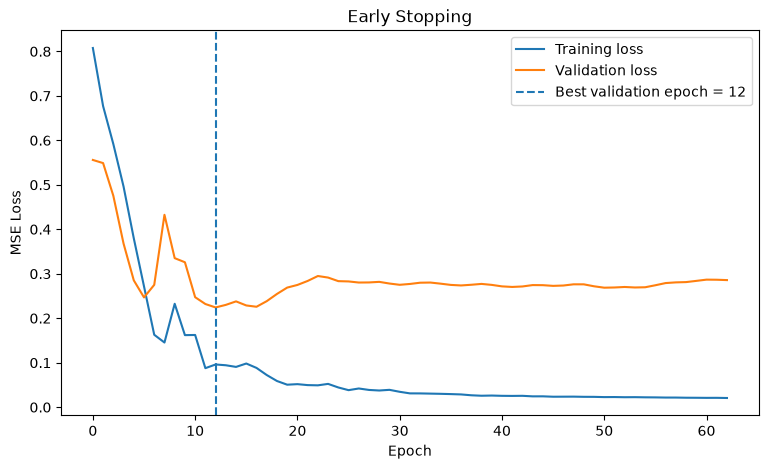

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses_early,
    label="Training loss"
)

plt.plot(
    val_losses_early,
    label="Validation loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best validation epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Early Stopping")
plt.legend()
plt.show()

## Early Stopping — Interpretation

Early stopping successfully prevented the model from continuing to overfit for
thousands of epochs.

The results were:

```text
Best validation epoch:      12
Early stopping triggered:   62
Epochs actually trained:    63

Best validation loss:       0.224296
Restored training loss:     0.094303
Restored validation loss:   0.224296
```

### Why did training stop at epoch 62 instead of epoch 12?

The patience value was:

```text
patience = 50
```

The best validation result occurred at:

```text
epoch 12
```

After that, validation loss did not improve for 50 consecutive epochs.

Therefore:

```text
12 + 50 = 62
```

and early stopping triggered.

The extra epochs provide a buffer in case validation temporarily becomes worse
and later improves again.

---

## Why restore the best model?

The model at the moment training stops is not necessarily the model with the
best validation performance.

Conceptually:

```text
epoch 12
→ best validation model

epochs 13–62
→ continued training
→ no better validation result

epoch 62
→ stopping condition reached
```

If we simply kept the final parameters from epoch 62, we would keep a model that
generalizes worse than the model from epoch 12.

Instead, we saved:

```python
early_stop_model.state_dict()
```

whenever validation improved.

After training stopped, we restored that saved state.

Therefore:

```text
restored validation loss
=
best validation loss
```

---

## Training loss at the restored checkpoint

The restored training loss was:

```text
0.094303
```

This is much higher than the approximately:

```text
0.000231
```

training loss reached during the deliberately overfit 2,000-epoch experiment.

But the validation behavior is better.

This demonstrates an important principle:

> A model with higher training loss can be a better model if it generalizes
> better to unseen data.

The objective is not necessarily to minimize training loss as far as possible.

The objective is usually to find parameters that perform well on data outside
the training set.

---

## Patience

Patience controls how long training continues without validation improvement.

For example:

```text
patience = 5
→ stop quickly

patience = 50
→ allow a larger window for possible recovery

patience = 200
→ train much longer before stopping
```

A patience value that is too small may stop training because of temporary
validation noise.

A patience value that is too large may waste compute and allow more unnecessary
training.

Like learning rate and momentum, patience is a hyperparameter.

---

## Key takeaway

Early stopping changes the training objective from:

```text
train for a fixed number of epochs
```

to something closer to:

```text
train while generalization is improving
```

The pattern is:

```text
training
    ↓
validation improves
    ↓
save checkpoint
    ↓
continue training
    ↓
validation stops improving
    ↓
wait for patience window
    ↓
stop
    ↓
restore best checkpoint
```

The final training state and the best model state are not necessarily the same.

```text
last checkpoint
≠
best checkpoint
```

## Regularization with Weight Decay

Early stopping controls **how long** we train.

Regularization takes a different approach:

> make it harder for the model to use unnecessarily large or complex parameter values.

One common technique is **weight decay**.

Conceptually, instead of only minimizing prediction error:

```text
prediction error
```

we also discourage large parameter values:

```text
prediction error
+
penalty on large weights
```

A simplified objective looks like:

$$
L_{\text{total}}
=
L_{\text{data}}
+
\lambda \lVert W \rVert^2
$$

where:

- $L_{\text{data}}$ = ordinary training loss
- $W$ = model weights
- $\lambda$ = regularization strength

A larger $\lambda$ means stronger pressure toward smaller weights.

### Why might this help?

A highly flexible model can sometimes fit tiny details or noise in the training
set by using complicated parameter configurations.

Weight decay discourages some of that behavior.

Conceptually:

```text
without regularization
→ fit training data as aggressively as possible

with regularization
→ fit training data
+
prefer simpler/smaller parameter values
```

This may increase training loss slightly while improving validation performance.

That tradeoff is often desirable.

---

## AdamW and Weight Decay

We will use:

```python
torch.optim.AdamW
```

because AdamW applies weight decay separately from Adam's adaptive gradient
update.

We will compare:

```text
weight_decay = 0.0
weight_decay = 0.01
weight_decay = 0.1
```

The goal is to observe how regularization strength affects both training and
validation behavior.

The squared-weight objective above motivates L2 regularization; AdamW applies decoupled parameter shrinkage rather than differentiating that augmented objective through Adam. The plotted losses remain data MSE. All model parameters, including biases, receive decay in this experiment. Expect stronger decay to resist fitting, but measure whether validation actually improves.

In [21]:
def train_with_weight_decay(weight_decay, epochs=500):
    # Same initialization for a fair comparison
    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(1, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    loss_fn = nn.MSELoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.01,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        # Training
        model.train()

        optimizer.zero_grad()

        train_pred = model(x_train_small)
        train_loss = loss_fn(train_pred, y_train_small)

        train_loss.backward()
        optimizer.step()

        # Validation
        model.eval()

        with torch.no_grad():
            val_pred = model(x_val_large)
            val_loss = loss_fn(val_pred, y_val_large)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

    return {
        "weight_decay": weight_decay,
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "final_train_loss": train_losses[-1],
        "final_val_loss": val_losses[-1],
        "best_val_loss": min(val_losses),
        "best_val_epoch": val_losses.index(min(val_losses)),
    }

In [22]:
no_decay = train_with_weight_decay(
    weight_decay=0.0
)

medium_decay = train_with_weight_decay(
    weight_decay=0.01
)

strong_decay = train_with_weight_decay(
    weight_decay=0.1
)

for result in [no_decay, medium_decay, strong_decay]:
    print(
        f"weight_decay={result['weight_decay']:<4} | "
        f"final train={result['final_train_loss']:.6f} | "
        f"final val={result['final_val_loss']:.6f} | "
        f"best val={result['best_val_loss']:.6f} | "
        f"best epoch={result['best_val_epoch']}"
    )

weight_decay=0.0  | final train=0.000468 | final val=0.338841 | best val=0.224296 | best epoch=12
weight_decay=0.01 | final train=0.004236 | final val=0.367285 | best val=0.224783 | best epoch=12
weight_decay=0.1  | final train=0.005239 | final val=0.348813 | best val=0.222337 | best epoch=12


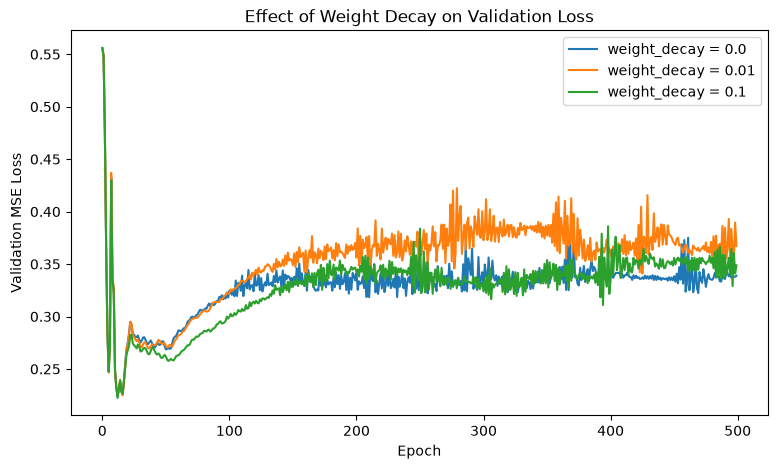

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    no_decay["val_losses"],
    label="weight_decay = 0.0"
)

plt.plot(
    medium_decay["val_losses"],
    label="weight_decay = 0.01"
)

plt.plot(
    strong_decay["val_losses"],
    label="weight_decay = 0.1"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE Loss")
plt.title("Effect of Weight Decay on Validation Loss")
plt.legend()
plt.show()

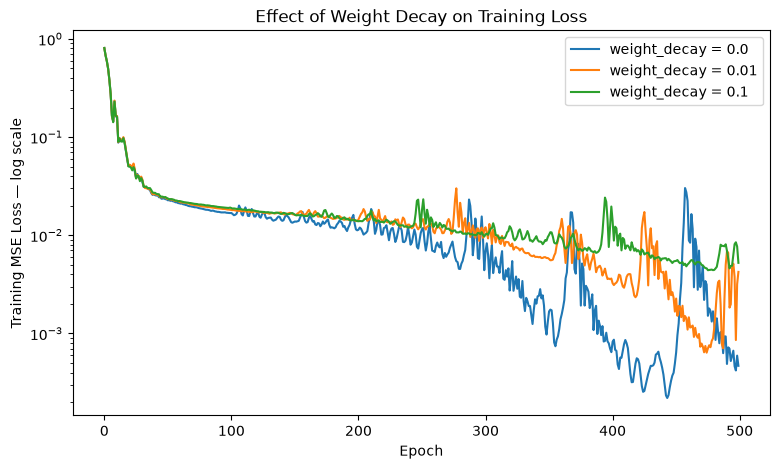

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    no_decay["train_losses"],
    label="weight_decay = 0.0"
)

plt.plot(
    medium_decay["train_losses"],
    label="weight_decay = 0.01"
)

plt.plot(
    strong_decay["train_losses"],
    label="weight_decay = 0.1"
)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss — log scale")
plt.title("Effect of Weight Decay on Training Loss")
plt.legend()
plt.show()

## Weight Decay — Interpretation

The weight-decay experiment produced:

```text
weight_decay = 0.0
final training loss   = 0.000468
final validation loss = 0.338841
best validation loss  = 0.224296
best epoch            = 12

weight_decay = 0.01
final training loss   = 0.004236
final validation loss = 0.367285
best validation loss  = 0.224783
best epoch            = 12

weight_decay = 0.1
final training loss   = 0.005239
final validation loss = 0.348813
best validation loss  = 0.222337
best epoch            = 12
```

### What did weight decay change?

As weight decay increased, the model became less aggressive at fitting the
training data.

Without weight decay:

```text
training loss ≈ 0.00047
```

With stronger weight decay:

```text
training loss ≈ 0.00524
```

So regularization successfully discouraged the model from fitting the tiny
training set as precisely.

This is the expected effect.

---

## Did weight decay improve generalization?

Only slightly in this experiment.

The best validation losses were:

```text
no decay     → 0.224296
decay = 0.01 → 0.224783
decay = 0.1  → 0.222337
```

The strongest weight decay produced the best validation loss, but the
improvement was small.

All three runs also reached their best validation performance around:

```text
epoch 12
```

and then validation performance became worse.

So weight decay did not eliminate overfitting.

---

## Why did training loss increase?

Weight decay discourages large model weights.

Conceptually, instead of optimizing only:

$$
L_{\text{data}}
$$

we introduce pressure toward smaller parameter values:

$$
L_{\text{total}}
=
L_{\text{data}}
+
\lambda \lVert W \rVert^2
$$

The model is therefore balancing two goals:

```text
fit the training data
+
avoid unnecessarily large weights
```

Because of this constraint, the regularized model may not fit the training data
as perfectly.

That is intentional.

A slightly higher training loss can be acceptable if validation performance
improves.

---

## Regularization is a tradeoff

Too little regularization can allow:

```text
very low training loss
+
poor generalization
```

Too much regularization can prevent the model from learning enough:

```text
high training loss
+
high validation loss
```

This second failure mode is called **underfitting**.

Conceptually:

```text
too little regularization
→ overfitting

appropriate regularization
→ better generalization

too much regularization
→ underfitting
```

---

## Early stopping vs weight decay

These techniques attack overfitting differently.

### Early stopping

Controls:

```text
how long the model is allowed to train
```

It stops when validation performance stops improving.

### Weight decay

Controls:

```text
how freely the model parameters can grow
```

It changes the optimization process itself by discouraging large parameter
values.

So:

```text
early stopping
→ temporal control

weight decay
→ parameter regularization
```

They can also be used together.

---

## What did this experiment teach us?

Weight decay clearly reduced the model's ability to memorize the training set:

```text
training loss increased
```

but it only slightly improved the best validation result.

The dominant problem in this setup was that the model began overfitting very
early.

That is why early stopping was especially effective.

The best validation epoch remained approximately:

```text
epoch 12
```

for all three weight-decay settings.

---

## Bias–variance intuition

A highly flexible model can have:

```text
low bias
high variance
```

meaning it can fit the training data extremely well but may be sensitive to the
specific examples it was given.

Regularization reduces some of that flexibility.

Very roughly:

```text
more model flexibility
→ lower bias
→ potentially higher variance

more regularization
→ potentially higher bias
→ potentially lower variance
```

The goal is not to minimize either bias or variance independently.

The goal is to find a balance that generalizes well.

---

## Key takeaway

Regularization is not guaranteed to improve validation performance dramatically.

Its effect depends on:

```text
model size
training data size
learning rate
optimizer
regularization strength
training duration
noise level
```

In this experiment:

```text
weight decay
→ reduced training-set memorization
→ slightly improved the best validation result
→ did not prevent later overfitting
```

Early stopping remained the stronger intervention for this particular setup.

## Model Capacity — Underfitting vs Overfitting

Model capacity describes how flexible a model is.

A model with low capacity may be too simple to represent the underlying pattern.

A model with very high capacity may fit the training data extremely well, including noise and sample-specific details.

Conceptually:

```text
too little capacity
→ underfitting

appropriate capacity
→ useful fit + good generalization

too much capacity
→ higher risk of overfitting
```

We will compare three models using the exact same:

```text
training data
validation data
optimizer
learning rate
number of epochs
```

Only the model capacity will change.

This is important because a fair experiment should change one major variable at a time.

Keep the dataset, learning rate, and 500-epoch budget fixed. Expect the small model to risk underfitting and the large model to risk fitting noise; compare validation rather than selecting by parameter count alone. Bias/variance is the intuition for this tradeoff, not a measured decomposition from this single split.

In [25]:
def make_model(size):
    if size == "small":
        # Very limited capacity
        return nn.Sequential(
            nn.Linear(1, 4),
            nn.ReLU(),
            nn.Linear(4, 1)
        )

    elif size == "medium":
        # More flexible
        return nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    elif size == "large":
        # High capacity relative to only 20 training examples
        return nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    else:
        raise ValueError(f"Unknown size: {size}")

In [26]:
def train_capacity_model(size, epochs=500):
    torch.manual_seed(42)

    model = make_model(size)

    loss_fn = nn.MSELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.01
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        # Training
        model.train()

        optimizer.zero_grad()

        train_pred = model(x_train_small)
        train_loss = loss_fn(
            train_pred,
            y_train_small
        )

        train_loss.backward()
        optimizer.step()

        # Validation
        model.eval()

        with torch.no_grad():
            val_pred = model(x_val_large)
            val_loss = loss_fn(
                val_pred,
                y_val_large
            )

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

    num_parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return {
        "size": size,
        "model": model,
        "parameters": num_parameters,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "final_train_loss": train_losses[-1],
        "final_val_loss": val_losses[-1],
        "best_val_loss": min(val_losses),
        "best_val_epoch": val_losses.index(min(val_losses)),
    }

In [27]:
small_model_result = train_capacity_model("small")
medium_model_result = train_capacity_model("medium")
large_model_result = train_capacity_model("large")

for result in [
    small_model_result,
    medium_model_result,
    large_model_result
]:
    print(
        f"{result['size']:<6} | "
        f"params={result['parameters']:<5} | "
        f"final train={result['final_train_loss']:.6f} | "
        f"final val={result['final_val_loss']:.6f} | "
        f"best val={result['best_val_loss']:.6f} | "
        f"best epoch={result['best_val_epoch']}"
    )

small  | params=13    | final train=0.209123 | final val=0.369255 | best val=0.342802 | best epoch=129
medium | params=321   | final train=0.022139 | final val=0.247215 | best val=0.213460 | best epoch=43
large  | params=8513  | final train=0.000468 | final val=0.338841 | best val=0.224296 | best epoch=12


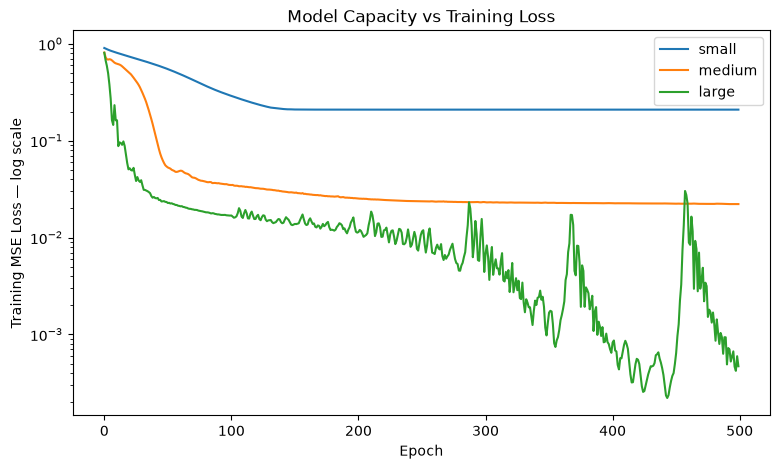

In [28]:
plt.figure(figsize=(9, 5))

for result in [
    small_model_result,
    medium_model_result,
    large_model_result
]:
    plt.plot(
        result["train_losses"],
        label=result["size"]
    )

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss — log scale")
plt.title("Model Capacity vs Training Loss")
plt.legend()
plt.show()

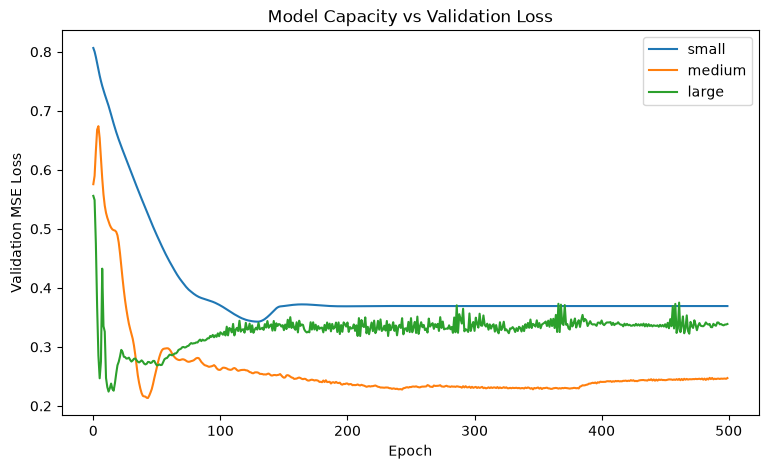

In [29]:
plt.figure(figsize=(9, 5))

for result in [
    small_model_result,
    medium_model_result,
    large_model_result
]:
    plt.plot(
        result["val_losses"],
        label=result["size"]
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE Loss")
plt.title("Model Capacity vs Validation Loss")
plt.legend()
plt.show()

## Model Capacity — Interpretation

The capacity experiment compared three models using the same:

```text
training data
validation data
optimizer
learning rate
number of epochs
```

Only the model size changed.

The results were:

```text
small model
parameters = 13
final training loss   = 0.209123
final validation loss = 0.369255
best validation loss  = 0.342802
best epoch            = 129

medium model
parameters = 321
final training loss   = 0.022139
final validation loss = 0.247215
best validation loss  = 0.213460
best epoch            = 43

large model
parameters = 8,513
final training loss   = 0.000468
final validation loss = 0.338841
best validation loss  = 0.224296
best epoch            = 12
```

---

### Small model — underfitting

The small model had only:

```text
13 trainable parameters
```

Its training loss remained relatively high:

```text
0.209123
```

and its validation loss was also high:

```text
0.369255
```

This suggests the model did not have enough capacity to represent the nonlinear
relationship well.

Conceptually:

```text
model too simple
      ↓
cannot fit training pattern well
      ↓
training loss remains high
      ↓
validation loss also remains high
```

This is **underfitting**.

---

### Medium model — best balance

The medium model had:

```text
321 trainable parameters
```

It achieved:

```text
training loss ≈ 0.022
best validation loss ≈ 0.213
```

This was the best validation result of the three models.

The model had enough capacity to learn the underlying nonlinear relationship,
but not so much capacity that it immediately memorized the tiny training set.

Conceptually:

```text
enough capacity
      ↓
learn useful signal
      ↓
reasonable training fit
      ↓
best generalization
```

For this dataset and training setup, the medium model provided the best
capacity–generalization tradeoff.

---

### Large model — overfitting

The large model had:

```text
8,513 trainable parameters
```

for only:

```text
20 training examples
```

It drove training loss almost to zero:

```text
0.000468
```

but the final validation loss was much worse:

```text
0.338841
```

Its best validation result occurred very early:

```text
epoch 12
```

After that, training loss continued decreasing while validation performance
became worse.

This is classic overfitting.

Conceptually:

```text
very high capacity
      ↓
learn useful signal quickly
      ↓
continue fitting training-specific details and noise
      ↓
training loss becomes extremely small
      ↓
generalization deteriorates
```

---

## Training loss alone can be misleading

The final training losses were:

```text
small  → 0.209123
medium → 0.022139
large  → 0.000468
```

If we looked only at training loss, we might conclude:

```text
large > medium > small
```

But validation tells a different story.

The best validation losses were:

```text
small  → 0.342802
medium → 0.213460
large  → 0.224296
```

So the medium model generalized best.

This demonstrates:

> The model that fits the training data best is not necessarily the best model.

---

## Underfitting vs good fit vs overfitting

The three models illustrate the full spectrum:

```text
small model
→ underfitting

medium model
→ best balance

large model
→ overfitting
```

A useful mental model is:

```text
model capacity increases →

underfitting
     ↓
good generalization
     ↓
overfitting risk
```

Too little capacity:

```text
high training loss
high validation loss
```

Appropriate capacity:

```text
lower training loss
low validation loss
```

Too much capacity:

```text
very low training loss
higher validation loss
```

---

## Bias–variance interpretation

Very roughly:

```text
small model
→ higher bias
→ lower flexibility

large model
→ lower bias
→ higher variance
```

The small model is too constrained to represent the true pattern.

The large model is flexible enough to fit not only the true pattern but also
noise and idiosyncrasies in the tiny training sample.

The medium model sits between those extremes.

---

## Why does the large model overfit earlier?

The best validation epochs were:

```text
small  → 129
medium → 43
large  → 12
```

As model capacity increased, the model was able to fit the training data more
quickly.

The large model therefore reached useful generalization early and then began
specializing to the training examples.

This reinforces why validation monitoring and early stopping become increasingly
important for high-capacity models.

---

## Key takeaway

Model quality depends on more than training loss.

We must consider:

```text
model capacity
training data size
noise
regularization
training duration
validation behavior
```

For this experiment:

```text
small model
→ too simple

medium model
→ best generalization

large model
→ strongest training fit but clear overfitting
```

The best model is not the largest model.

The best model is the one that generalizes best to the data distribution we
actually care about.

## Module 1 — What We Learned

tensor → parameter → prediction → loss → gradient → optimizer → training → validation → generalization → overfitting → regularization

Tensors carry values, shapes, and gradient metadata. Parameters produce predictions; loss measures error; backward computes derivatives; the optimizer turns them into updates. Inspect shapes, clear gradients, and choose learning rates by measured behavior.

Training success is only the first check. The flexible model fit 20 examples almost perfectly while validation favored epoch 12. Restoring the best checkpoint, adding weight decay, and choosing suitable capacity control different parts of that failure mode. The medium model generalized better in this experiment; stronger regularization and larger models do not guarantee improvement.

Keep seeds and settings explicit, compare held-out behavior, and distinguish the last training state from the best validation state. Use a separate test set after selecting models with validation.